Test Data Shape: (123, 21)
Features: (123, 20)
Target: (123,)
Logistic Regression loaded successfully
Decision Tree loaded successfully
Random Forest loaded successfully
XGBoost loaded successfully


MODEL EVALUATION SUMMARY


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,86.99%,84.85%,98.82%,91.30%,0.8728
1,Random Forest,86.18%,84.69%,97.65%,90.71%,0.8737
2,Decision Tree,84.55%,84.38%,95.29%,89.50%,0.7515
3,XGBoost,82.93%,85.56%,90.59%,88.00%,0.8511



Evaluation results saved:
../data/model_evaluation.csv


CLASSIFICATION REPORT — Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.96      0.61      0.74        38
    Approved       0.85      0.99      0.91        85

    accuracy                           0.87       123
   macro avg       0.90      0.80      0.83       123
weighted avg       0.88      0.87      0.86       123



CLASSIFICATION REPORT — Decision Tree
              precision    recall  f1-score   support

    Rejected       0.85      0.61      0.71        38
    Approved       0.84      0.95      0.90        85

    accuracy                           0.85       123
   macro avg       0.85      0.78      0.80       123
weighted avg       0.85      0.85      0.84       123



CLASSIFICATION REPORT — Random Forest
              precision    recall  f1-score   support

    Rejected       0.92      0.61      0.73        38
    Approved       0.85      0.98      0.91        85



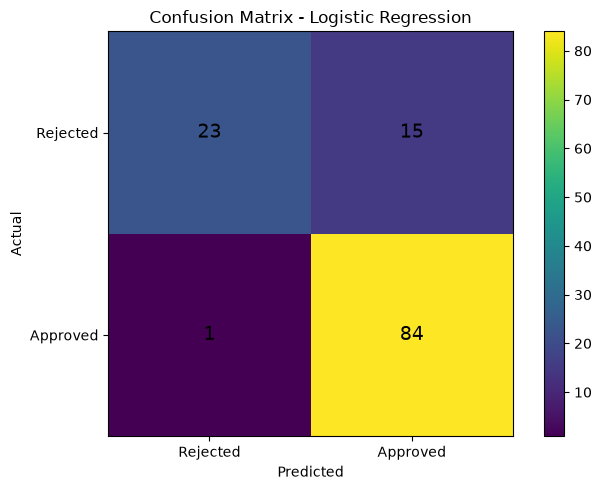

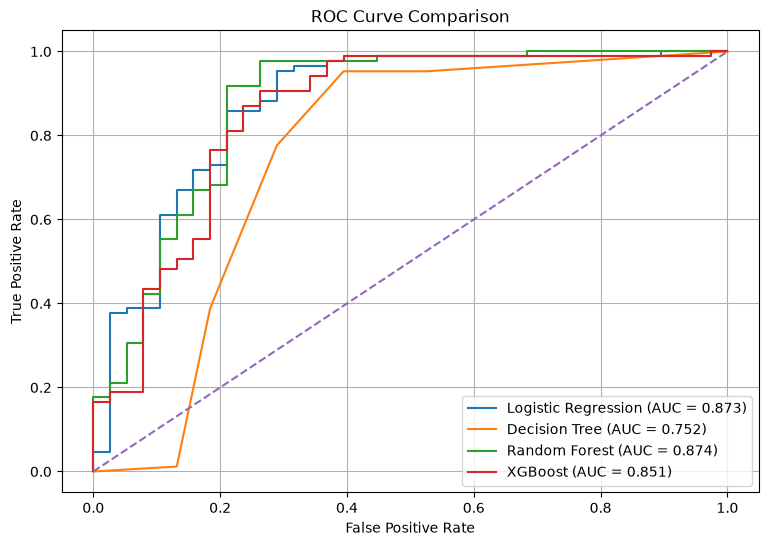



BUSINESS INTERPRETATION

1. Accuracy:
   Shows the overall percentage of correct predictions.

2. Precision:
   Shows how many predicted approvals were actually approved.

3. Recall:
   Shows how many actual approved applications were correctly identified.

4. F1 Score:
   Provides a balance between Precision and Recall.

5. ROC-AUC:
   Measures how effectively the model separates approved
   and rejected loan applications.

6. Confusion Matrix:
   Helps identify false approvals and false rejections.

7. Feature Importance:
   Shows which applicant characteristics have the strongest
   influence on the model's predictions.



FINAL MODEL DECISION
Selected Model : Logistic Regression
Accuracy       : 86.99%
Precision      : 84.85%
Recall         : 98.82%
F1 Score       : 91.30%
ROC-AUC        : 0.8728

Final model saved:
../models/final_loan_model.pkl


MODEL EVALUATION COMPLETED SUCCESSFULLY! ✅


In [1]:
# ============================================================
# LOAN APPROVAL & RISK ANALYTICS
# STEP 6: MODEL EVALUATION
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import joblib
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


# ------------------------------------------------------------
# 2. Load Test Data
# ------------------------------------------------------------

test_data = pd.read_csv("../data/test_data.csv")

X_test = test_data.drop("Loan_Status", axis=1)
y_test = test_data["Loan_Status"]

print("Test Data Shape:", test_data.shape)
print("Features:", X_test.shape)
print("Target:", y_test.shape)


# ------------------------------------------------------------
# 3. Load Trained Models
# ------------------------------------------------------------

model_files = {
    "Logistic Regression": "../models/logistic_regression.pkl",
    "Decision Tree": "../models/decision_tree.pkl",
    "Random Forest": "../models/random_forest.pkl",
    "XGBoost": "../models/xgboost.pkl"
}

models = {}

for name, path in model_files.items():

    models[name] = joblib.load(path)

    print(f"{name} loaded successfully")


# ------------------------------------------------------------
# 4. Evaluate All Models
# ------------------------------------------------------------

evaluation_results = []

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # ROC-AUC
    if hasattr(model, "predict_proba"):

        y_probability = model.predict_proba(X_test)[:, 1]

        auc_score = roc_auc_score(
            y_test,
            y_probability
        )

    else:
        auc_score = np.nan

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc_score
    })


# ------------------------------------------------------------
# 5. Evaluation Summary
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n")
print("=" * 90)
print("MODEL EVALUATION SUMMARY")
print("=" * 90)

display(
    evaluation_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.4f}"
    })
)


# ------------------------------------------------------------
# 6. Save Evaluation Results
# ------------------------------------------------------------

evaluation_df.to_csv(
    "../data/model_evaluation.csv",
    index=False
)

print("\nEvaluation results saved:")
print("../data/model_evaluation.csv")


# ------------------------------------------------------------
# 7. Classification Reports
# ------------------------------------------------------------

for name, y_pred in predictions.items():

    print("\n")
    print("=" * 70)
    print(f"CLASSIFICATION REPORT — {name}")
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Rejected", "Approved"],
            zero_division=0
        )
    )


# ------------------------------------------------------------
# 8. Confusion Matrix for Best Model
# ------------------------------------------------------------

best_model_name = evaluation_df.iloc[0]["Model"]

best_model = models[best_model_name]

best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions
)

print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print("Best Model:", best_model_name)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 9. Plot Confusion Matrix
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.imshow(cm)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Rejected", "Approved"]
)

plt.yticks(
    [0, 1],
    ["Rejected", "Approved"]
)

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. ROC Curves
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for name, model in models.items():

    if hasattr(model, "predict_proba"):

        y_probability = model.predict_proba(X_test)[:, 1]

        fpr, tpr, _ = roc_curve(
            y_test,
            y_probability
        )

        auc_score = roc_auc_score(
            y_test,
            y_probability
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC = {auc_score:.3f})"
        )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()

plt.grid()

plt.show()


# ------------------------------------------------------------
# 11. Feature Importance
# ------------------------------------------------------------

if hasattr(best_model, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": best_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    print("\n")
    print("=" * 70)
    print("TOP 15 IMPORTANT FEATURES")
    print("=" * 70)

    display(importance_df)


    # Plot feature importance

    plt.figure(figsize=(10, 6))

    plt.barh(
        importance_df["Feature"][::-1],
        importance_df["Importance"][::-1]
    )

    plt.xlabel("Importance")

    plt.ylabel("Feature")

    plt.title(
        f"Top 15 Features - {best_model_name}"
    )

    plt.tight_layout()

    plt.show()


# ------------------------------------------------------------
# 12. Business Interpretation
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("BUSINESS INTERPRETATION")
print("=" * 80)

print("""
1. Accuracy:
   Shows the overall percentage of correct predictions.

2. Precision:
   Shows how many predicted approvals were actually approved.

3. Recall:
   Shows how many actual approved applications were correctly identified.

4. F1 Score:
   Provides a balance between Precision and Recall.

5. ROC-AUC:
   Measures how effectively the model separates approved
   and rejected loan applications.

6. Confusion Matrix:
   Helps identify false approvals and false rejections.

7. Feature Importance:
   Shows which applicant characteristics have the strongest
   influence on the model's predictions.
""")


# ------------------------------------------------------------
# 13. Final Model Decision
# ------------------------------------------------------------

best_row = evaluation_df.iloc[0]

print("\n")
print("=" * 80)
print("FINAL MODEL DECISION")
print("=" * 80)

print("Selected Model :", best_row["Model"])
print("Accuracy       :", f"{best_row['Accuracy']:.2%}")
print("Precision      :", f"{best_row['Precision']:.2%}")
print("Recall         :", f"{best_row['Recall']:.2%}")
print("F1 Score       :", f"{best_row['F1 Score']:.2%}")
print("ROC-AUC        :", f"{best_row['ROC-AUC']:.4f}")


# ------------------------------------------------------------
# 14. Save Final Model
# ------------------------------------------------------------

joblib.dump(
    best_model,
    "../models/final_loan_model.pkl"
)

print("\nFinal model saved:")
print("../models/final_loan_model.pkl")


# ------------------------------------------------------------
# 15. Completion Check
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("MODEL EVALUATION COMPLETED SUCCESSFULLY! ✅")
print("=" * 80)